<a href="https://colab.research.google.com/github/silvatria/pembelajaran-mesin-254107023001/blob/main/JS08_TL02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumlah cluster yang terbentuk: 2
Banyaknya data noise: 2


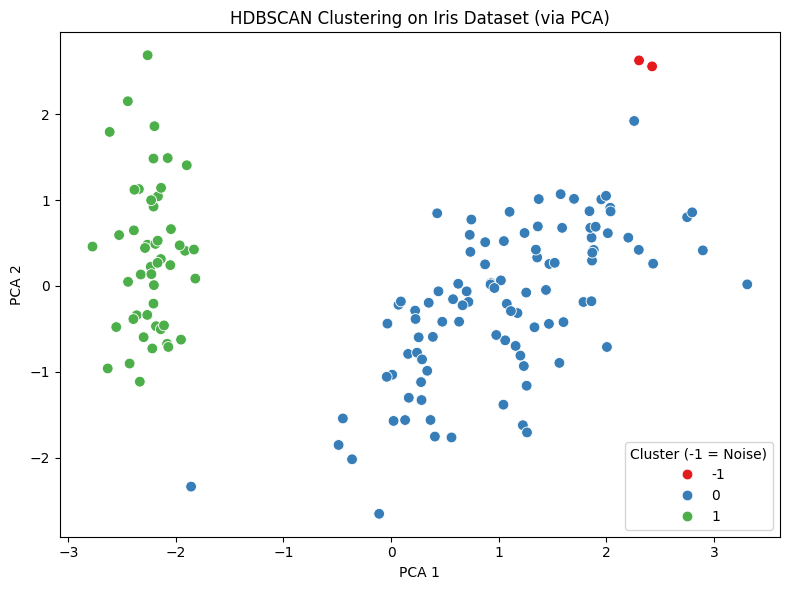

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import hdbscan
import sklearn.metrics as metrics

# 1. Load dataset Iris dari sklearn
iris = load_iris()
X = iris.data
y_true = iris.target  # Label asli (ground truth)

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Lakukan clustering dengan HDBSCAN
# min_cluster_size diatur agar pas dengan ukuran dataset Iris (150 baris)
clusterer = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5)
clusterer.fit(X_scaled)

# Hasil klaster & noise (-1 artinya noise)
labels = clusterer.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"Jumlah cluster yang terbentuk: {n_clusters}")
print(f"Banyaknya data noise: {n_noise}")

# 3. Reduksi Dimensi dengan PCA (dari 4D ke 2D) untuk Visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_vis = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
df_vis['Cluster'] = labels
df_vis['True_Label'] = y_true

# 4. Visualisasi Scatterplot (diperbaiki tanpa parameter 'deep')
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_vis,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1',
    s=60,
)
plt.title('HDBSCAN Clustering on Iris Dataset (via PCA)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend(title='Cluster (-1 = Noise)')
plt.tight_layout()
plt.show()

# ==========================================
# LAPORAN TUGAS LAB 2: HDBSCAN CLUSTERING
# ==========================================

# 1. HASIL CLUSTERING HDBSCAN:
#    - Jumlah cluster yang terbentuk: 2 cluster utama (Cluster 0 dan Cluster 1).
#    - Banyaknya data noise: Terdapat 2 data yang terdeteksi sebagai noise (berlabel -1).

# 2. VISUALISASI REDUKSI DIMENSI (PCA):
#    - Reduksi dimensi dilakukan dari 4 fitur asli ke 2 komponen utama (PCA1 & PCA2).
#    - Visualisasi menunjukkan HDBSCAN berhasil memisahkan satu spesies dengan bersih (klaster hijau),
#      sementara dua spesies lainnya tergabung dalam satu klaster besar (klaster biru) dengan beberapa noise (titik merah).

# 3. ANALISIS SINGKAT:
#    - Apakah sesuai dengan label asli dataset?
#      Cukup sesuai secara struktur data alami, tetapi berbeda dalam jumlah kelasnya.
#    - Penjelasan:
#      Label asli (ground truth) Iris dataset memiliki 3 kelas (Setosa, Versicolor, Virginica).
#      Namun, secara spasial, karakteristik Versicolor dan Virginica memiliki irisan (overlap) yang tinggi.
#      Oleh karena itu, algoritma berbasis densitas seperti HDBSCAN menggabungkan keduanya ke dalam satu klaster,
#      sementara kelas Setosa berhasil dipisahkan dengan sempurna sebagai klaster tersendiri karena terpisah jauh.